# Metaheuristics for Multi-Resource Workload Allocation

## Problem Definition

This coursework investigates a multi-resource model selection problem.
Each candidate model has a utility value and consumes several resources.
The objective is to select a subset of models that maximises total utility
without exceeding any resource capacity.

A solution is represented by a binary vector: 1 means a model is selected,
and 0 means it is not selected.

## 1. Data loading

NumPy is used to store and calculate model utilities and resource demands.
The loading function follows the structure of the lecturer-provided loader,
with an additional check on the number of data entries.

The file contains the number of models (n), the number of resources (m),
n utility values, m × n resource demands, and m capacity limits, in that order.
The resource demand matrix has shape (m, n): each row represents a resource,
and each column represents a model.

The two lecturer-provided data files are included alongside this
notebook. Keep both files in the same directory as the notebook
and run the notebook from that directory.

In [2]:
import numpy as np


def load_workload_instance(file_path):
    """Read model utilities, resource demands and capacities."""
    with open(file_path, "r", encoding="utf-8") as f:
        tokens = f.read().split()

    n = int(tokens[0])
    m = int(tokens[1])

    expected_count = 2 + n + m * n + m
    if len(tokens) != expected_count:
        raise ValueError("The data quantity is incorrect. Please check the data file.")

    idx = 2

    utilities = np.array(
        tokens[idx:idx + n], dtype=float
    )
    idx += n

    demands = np.array(
        tokens[idx:idx + m * n], dtype=float
    ).reshape(m, n)
    idx += m * n

    capacities = np.array(
        tokens[idx:idx + m], dtype=float
    )

    return n, m, utilities, demands, capacities

## 2. Instance 1: Data Summary

Instance 1 contains 28 candidate models and two resource constraints,
each with a capacity of 500. It is used to develop and evaluate the
baseline hill-climbing algorithm in Part 1.

The following output reports the instance dimensions and capacity limits
to check that they match the assignment specification.

In [3]:
n, m, utilities, demands, capacities = load_workload_instance(
   "multi_resource_n28_m2.txt"
)

print("Number of models:", n)
print("Number of resources:", m)
print("Resource capacities:", capacities)

Number of models: 28
Number of resources: 2
Resource capacities: [500. 500.]


## 3. Solution Representation and Evaluation

A solution is represented by a binary vector of length n.
A value of 1 selects a model, while 0 excludes it.

The total utility and resource usage are calculated by summing
the contributions of the selected models. A solution is feasible
only if every resource usage is within its capacity.

Selecting models 1 and 3 gives a total utility of 24,405 and resource usage of 130 and 155. Both resource usages are below their respective capacities of 500, so the solution is feasible.

This manually constructed example checks the evaluation calculation. It is not a claim that the solution is the best.

In [4]:
def evaluate_solution(x, utilities, demands, capacities):
    """Return total utility, resource usage and feasibility."""
    total_utility = utilities @ x
    resource_usage = demands @ x
    feasible = bool(np.all(resource_usage <= capacities))

    return total_utility, resource_usage, feasible


# Start with all models unselected.
x = np.zeros(n, dtype=int)

# Select model 1 and model 3.
x[0] = 1
x[2] = 1

value, usage, feasible = evaluate_solution(
    x, utilities, demands, capacities
)

print("Selection vector:", x)
print("Total utility:", value)
print("Resource usage:", usage)
print("Feasible:", feasible)

Selection vector: [1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Total utility: 24405.0
Resource usage: [130. 155.]
Feasible: True


### Feasibility Check

To check the constraint evaluation, all 28 models are selected.
This deliberately creates an infeasible solution, allowing us
to verify that the evaluation function detects resource violations.

In [5]:
# Select all 28 models.
x_all = np.ones(n, dtype=int)

value_all, usage_all, feasible_all = evaluate_solution(
    x_all, utilities, demands, capacities
)

print("Resource usage:", usage_all)
print("Resource capacities:", capacities)
print("Feasible:", feasible_all)

Resource usage: [1125.  995.]
Resource capacities: [500. 500.]
Feasible: False


Selecting all 28 models uses 1,125 units of resource 1 and 995 units of resource 2. Both exceed their capacities of 500, so the evaluation function correctly identifies this solution as infeasible.

## Part 1: Baseline Discrete Local Search

This part implements and evaluates a first-improvement hill climber
on Instance 1. It covers feasible initialisation, neighbourhood
operators, constraint handling, and performance across 30 independent runs.

### 4. Randomised Feasible Initialisation

The initial solution is constructed from an empty selection.
Models are considered in a random order and added only when all
resource constraints remain satisfied.

This provides a feasible starting point. Different random seeds
can produce different initial solutions. The empty solution and
each attempted addition are included in the evaluation count.

In [6]:
def create_initial_solution(utilities, demands, capacities, rng):
    n = len(utilities)
    x = np.zeros(n, dtype=int)

    value, usage, _ = evaluate_solution(
        x, utilities, demands, capacities
    )
    evaluations = 1

    for j in rng.permutation(n):
        candidate = x.copy()
        candidate[j] = 1

        new_value, new_usage, feasible = evaluate_solution(
            candidate, utilities, demands, capacities
        )
        evaluations += 1

        if feasible:
            x, value, usage = candidate, new_value, new_usage

    return x, value, usage, evaluations

### 5. Neighbourhood Operators

Two neighbourhood operators are used:

- Single-bit flip: change one model's selection status.
- One-for-one swap: remove one selected model and add one unselected model.

A swap can improve a capacity-limited solution when adding a model
alone would violate a constraint. Neighbours are evaluated during
the search, and infeasible candidates are rejected.

In [7]:
def generate_neighbors(x, rng):
    # Operator 1: flip one selection decision.
    for j in rng.permutation(len(x)):
        candidate = x.copy()
        candidate[j] = 1 - candidate[j]
        yield candidate

    # Operator 2: exchange one selected and one unselected model.
    selected = rng.permutation(np.flatnonzero(x == 1))
    unselected = rng.permutation(np.flatnonzero(x == 0))

    for remove in selected:
        for add in unselected:
            candidate = x.copy()
            candidate[remove] = 0
            candidate[add] = 1
            yield candidate

### 6. First-Improvement Hill Climbing

The search starts from a randomly constructed feasible solution.
Neighbours are examined in a randomised order: single-bit flips
are considered first, followed by one-for-one swaps.

The first feasible neighbour with strictly higher utility is accepted,
and neighbourhood exploration restarts from that solution.
Infeasible and non-improving candidates are rejected.

The search stops when a complete neighbourhood contains no improving
feasible solution, or when the evaluation budget is exhausted.
Initialisation and all evaluated neighbours count towards this budget.

Strict improvement prevents cycling, but the search may stop at a local optimum rather than a global optimum (Russell & Norvig, 2021).

In [8]:
def hill_climb(utilities, demands, capacities, seed=42,
               max_evaluations=5000):

    if max_evaluations < len(utilities) + 1:
        raise ValueError("Budget is too small for initialisation.")

    rng = np.random.default_rng(seed)

    x, value, usage, evaluations = create_initial_solution(
        utilities, demands, capacities, rng
    )

    initial_value = value
    history = [(evaluations, value)]
    stop_reason = "evaluation_budget"

    while evaluations < max_evaluations:
        improved = False

        for candidate in generate_neighbors(x, rng):
            if evaluations >= max_evaluations:
                break

            new_value, new_usage, feasible = evaluate_solution(
                candidate, utilities, demands, capacities
            )
            evaluations += 1

            if feasible and new_value > value:
                x, value, usage = candidate, new_value, new_usage
                improved = True

            history.append((evaluations, value))

            if improved:
                break

        if not improved:
            if evaluations < max_evaluations:
                stop_reason = "local_optimum"
            break

    return {
        "solution": x,
        "initial_value": initial_value,
        "value": value,
        "usage": usage,
        "evaluations": evaluations,
        "history": history,
        "stop_reason": stop_reason,
    }

### 7. Single-Run Demonstration

The hill climber is applied to Instance 1 using seed 42 and
a maximum budget of 5,000 evaluations.

This demonstration reports the improvement from the initial solution,
the final resource usage, and the reason for termination.
Multiple independent runs will be used later to assess performance.

In [9]:
result = hill_climb(
    utilities,
    demands,
    capacities,
    seed=42,
    max_evaluations=5000
)

print("Initial utility:", result["initial_value"])
print("Final utility:", result["value"])
print("Resource usage:", result["usage"])
print("Resource capacities:", capacities)
print("Evaluations:", result["evaluations"])
print("Stop reason:", result["stop_reason"])

print(
    "Selected models:",
    np.flatnonzero(result["solution"]) + 1
)

# Independently check the returned solution.
checked_value, checked_usage, checked_feasible = evaluate_solution(
    result["solution"], utilities, demands, capacities
)

print("Final solution feasible:", checked_feasible)

Initial utility: 74163.0
Final utility: 98003.0
Resource usage: [455. 494.]
Resource capacities: [500. 500.]
Evaluations: 498
Stop reason: local_optimum
Selected models: [ 1  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 23 24 27]
Final solution feasible: True


For seed 42, hill climbing increased utility from 74,163 to 98,003.
The final resource usages were 455 and 494, satisfying both
capacity limits of 500.

The search terminated after 498 evaluations because no improving
feasible neighbour remained under the defined neighbourhood.
This establishes local optimality for these operators, not global
optimality. A single run is insufficient to assess reliability.

### 8. Repeated Experiments

The hill climber is evaluated on Instance 1 over 30 independent runs,
using random seeds 0–29. Each run starts from a newly constructed
feasible solution and has a maximum budget of 5,000 evaluations,
including initialisation.

Runs terminate early when no improving feasible neighbour remains.
Final utility, evaluation count, termination reason and elapsed
search time are recorded. Final solutions are checked for feasibility.

Post-run validation is excluded from search time and evaluation counts.

In [10]:
from time import perf_counter

seeds = list(range(30))
budget = 5000
runs = []

for seed in seeds:
    start = perf_counter()

    run = hill_climb(
        utilities,
        demands,
        capacities,
        seed=seed,
        max_evaluations=budget
    )

    elapsed = perf_counter() - start

    # Check the returned solution after timing the search.
    checked_value, checked_usage, checked_feasible = evaluate_solution(
        run["solution"], utilities, demands, capacities
    )

    if not checked_feasible or not np.isclose(checked_value, run["value"]):
        raise RuntimeError(f"Invalid result for seed {seed}")

    run["seed"] = seed
    run["seconds"] = elapsed
    run["feasible"] = checked_feasible
    runs.append(run)

print(f"Completed {len(runs)} runs.")
print(f"Maximum evaluation budget per run: {budget}")

Completed 30 runs.
Maximum evaluation budget per run: 5000


### 9. Performance Summary

Final utility is summarised using the best, worst, mean, median
and sample standard deviation across runs. The standard deviation
describes variability between runs.

The mean improvement over initialisation, evaluation count and
elapsed search time are also reported. The best observed solution
is inspected for resource usage.

In [11]:
initial_values = np.array([run["initial_value"] for run in runs])
final_values = np.array([run["value"] for run in runs])
evaluation_counts = np.array([run["evaluations"] for run in runs])
times = np.array([run["seconds"] for run in runs])

gains = final_values - initial_values

# Show the results of individual runs.
print(
    f"{'Seed':>4} {'Initial':>10} {'Final':>10} "
    f"{'Gain':>10} {'Evaluations':>12} {'Seconds':>10}"
)

for run in runs:
    print(
        f"{run['seed']:4d} "
        f"{run['initial_value']:10.0f} "
        f"{run['value']:10.0f} "
        f"{run['value'] - run['initial_value']:10.0f} "
        f"{run['evaluations']:12d} "
        f"{run['seconds']:10.4f}"
    )

print("\nSummary across 30 runs")
print(f"Best final utility: {final_values.max():.0f}")
print(f"Worst final utility: {final_values.min():.0f}")
print(f"Mean final utility: {final_values.mean():.2f}")
print(f"Median final utility: {np.median(final_values):.2f}")
print(f"Sample standard deviation: {final_values.std(ddof=1):.2f}")
print(f"Mean improvement: {gains.mean():.2f}")
print(f"Mean evaluations: {evaluation_counts.mean():.2f}")
print(f"Mean search time (seconds): {times.mean():.4f}")

print(
    "Feasible final solutions:",
    sum(run["feasible"] for run in runs),
    "/",
    len(runs)
)

print(
    "Local-optimum stops:",
    sum(run["stop_reason"] == "local_optimum" for run in runs)
)

print(
    "Budget stops:",
    sum(run["stop_reason"] == "evaluation_budget" for run in runs)
)

# Inspect the best result among these 30 runs.
best_run = max(runs, key=lambda run: run["value"])

print("\nBest observed run")
print("Seed:", best_run["seed"])
print("Selected models:", np.flatnonzero(best_run["solution"]) + 1)
print("Resource usage:", best_run["usage"])

print(
    "Resource utilisation (%):",
    np.round(100 * best_run["usage"] / capacities, 1)
)

Seed    Initial      Final       Gain  Evaluations    Seconds
   0      60460      91232      30772          698     0.0099
   1      77945     109817      31872          762     0.0099
   2      99822     121164      21342          919     0.0114
   3      96849     110154      13305          612     0.0083
   4      93727     102737       9010          760     0.0271
   5     102492     115971      13479          716     0.0090
   6      77249     117360      40111         1099     0.0138
   7      95108      95108          0          217     0.0027
   8      73037      79767       6730          560     0.0068
   9      98259     110032      11773          491     0.0020
  10      99513     109152       9639          573     0.0027
  11      61363     101609      40246          968     0.0038
  12      85817     113286      27469          627     0.0024
  13     107994     113584       5590          602     0.0023
  14     105577     120844      15267          604     0.0024
  15    

### 10. Convergence and Result Distribution

The convergence plot shows median best-so-far feasible utility
across 30 runs. The shaded region represents the 25th–75th
percentiles and describes variability between runs.

Histories start after initialisation, which uses 29 evaluations.
When a run stops early, its final value is carried forward for
plot alignment; this does not represent additional evaluations.
The horizontal axis ends at the largest actual evaluation count.

Boxplots summarise the initial and final utility distributions
across the same 30 runs.

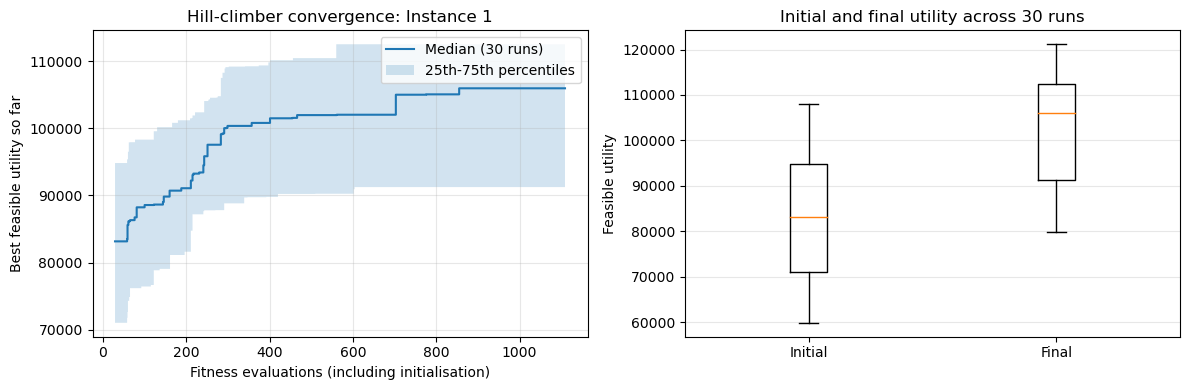

In [12]:
import matplotlib.pyplot as plt

# Use a common evaluation axis for all runs.
first_evaluation = max(run["history"][0][0] for run in runs)
last_evaluation = max(run["evaluations"] for run in runs)

evaluation_grid = np.arange(
    first_evaluation,
    last_evaluation + 1
)

curves = []

for run in runs:
    history = np.asarray(run["history"])

    # Find the latest recorded value at each evaluation point.
    indices = np.searchsorted(
        history[:, 0],
        evaluation_grid,
        side="right"
    ) - 1

    curves.append(history[indices, 1])

curves = np.asarray(curves)

q25, median_curve, q75 = np.percentile(
    curves,
    [25, 50, 75],
    axis=0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: convergence across runs.
axes[0].step(
    evaluation_grid,
    median_curve,
    where="post",
    label="Median (30 runs)"
)

axes[0].fill_between(
    evaluation_grid,
    q25,
    q75,
    step="post",
    alpha=0.2,
    label="25th-75th percentiles"
)

axes[0].set_xlabel("Fitness evaluations (including initialisation)")
axes[0].set_ylabel("Best feasible utility so far")
axes[0].set_title("Hill-climber convergence: Instance 1")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: initial and final utility distributions.
axes[1].boxplot([initial_values, final_values])
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Initial", "Final"])
axes[1].set_ylabel("Feasible utility")
axes[1].set_title("Initial and final utility across 30 runs")
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

### 11. Discussion of the Baseline

Across 30 independent runs, the hill climber achieved a mean final
utility of 102,592.93, with a sample standard deviation of 12,640.84.
Final utilities ranged from 79,732 to 121,164, indicating sensitivity
to the random initial solution and search order.

The mean improvement over initialisation was 20,093.67. All 30 final
solutions satisfied both resource constraints. The best observed
solution used 475 and 495 units of the two resources, corresponding
to 95% and 99% of their capacities.

The convergence plot shows increasing median utility followed by
smaller improvements. All runs terminated at local optima before
reaching the maximum budget, using a mean of 683.50 evaluations.
This suggests that termination under the chosen neighbourhood,
rather than the evaluation limit, restricted further progress.

Constraint handling is straightforward: infeasible candidates are
evaluated and rejected. This preserves feasibility but spends
evaluations on rejected moves and prevents exploration through
infeasible solutions.

One-for-one swaps allow improvements when direct additions are
blocked by resource limits. However, the neighbourhood cannot
directly express exchanges involving several removals or additions,
and strict improvement prevents temporary decreases in utility.
Consequently, the method can become trapped at different local optima.

The mean elapsed search time was 0.0053 seconds per run in the
current execution environment. This indicates a short runtime
on Instance 1, but does not establish scalability to Instance 2.
No global optimality claim is made.

## Part 2: Advanced Metaheuristic Engineering

This part develops a binary genetic algorithm for Instance 2,
which contains 90 candidate models and five resource constraints.

Each individual is represented by a binary vector. The population
contains multiple candidate solutions, which are evolved using
selection, crossover and mutation.

A binary genetic algorithm is chosen because each gene directly represents whether a model is selected. Its population-based search allows different selection patterns to be explored and recombined, while mutation introduces further changes (Eiben & Smith, 2015). Constraint repair is applied separately to ensure that individuals are feasible before evaluation.

### 12. Loading Instance 2

Instance 2 is used for the advanced population-based metaheuristic.
It contains 90 candidate models and five resource constraints, so the
resource demand matrix has shape (5, 90).

Separate variable names are used to retain the Instance 1 data for
the baseline experiments.

In [13]:
n2, m2, utilities2, demands2, capacities2 = load_workload_instance(
    "multi_resource_n90_m5.txt"
)

print("Number of models:", n2)
print("Number of resources:", m2)
print("Utility array shape:", utilities2.shape)
print("Resource demand matrix shape:", demands2.shape)
print("Resource capacities:", capacities2)

Number of models: 90
Number of resources: 5
Utility array shape: (90,)
Resource demand matrix shape: (5, 90)
Resource capacities: [2100. 1100. 3300. 3700. 3600.]


### 13. Greedy Constraint Repair

Crossover and mutation can create infeasible offspring.
A greedy repair procedure is therefore applied after these operations.

When a solution violates one or more resource constraints, the algorithm
scores each selected model by its utility relative to its normalised
consumption of the currently violated resources. Normalisation accounts for
the different resource capacities. The selected model with the lowest score
is removed, and the violated resources and scores are recalculated until
the solution becomes feasible.

The repair strategy preserves feasibility, although it is a heuristic
and does not guarantee the best possible repair.

In [14]:
def repair_solution_greedy(
    x,
    utilities,
    demands,
    capacities
):
    """
    Remove selected models until all resource constraints are satisfied.
    """
    x = np.asarray(x, dtype=np.int8).copy()

    while True:
        usage = demands @ x
        violated = usage > capacities

        if not np.any(violated):
            return x

        selected = np.flatnonzero(x == 1)

        # Only consider resource consumption on violated resources.
        normalised_cost = (
            demands[violated][:, selected]
            / capacities[violated, None]
        ).sum(axis=0)

        utility_density = (
            utilities[selected]
            / (normalised_cost + 1e-12)
        )

        # Remove the least efficient selected model.
        remove_position = np.argmin(utility_density)
        remove_model = selected[remove_position]
        x[remove_model] = 0

### 14. Initial Population

A genetic algorithm maintains a population rather than a single
current solution. Each randomly generated binary vector is repaired
before entering the population, so the initial population contains
only feasible solutions.

A population size of 60 is used as a compromise between population
diversity and computational cost. The same population size is
kept for all later algorithmic variants to ensure a fair comparison.

Random binary initialisation is used to generate varied starting selection patterns, while repair ensures feasibility before evaluation. However, repair can bias these patterns, and neither uniqueness nor population diversity is guaranteed or measured.

In [15]:
def initialise_population(
    population_size,
    utilities,
    demands,
    capacities,
    rng
):
    population = []

    for _ in range(population_size):
        random_solution = rng.integers(
            low=0,
            high=2,
            size=len(utilities),
            dtype=np.int8
        )

        feasible_solution = repair_solution_greedy(
            random_solution,
            utilities,
            demands,
            capacities
        )

        population.append(feasible_solution)

    return np.asarray(population, dtype=np.int8)

In [16]:
population_size = 60
rng = np.random.default_rng(42)

population = initialise_population(
    population_size,
    utilities2,
    demands2,
    capacities2,
    rng
)

population_values = np.array([
    evaluate_solution(
        individual,
        utilities2,
        demands2,
        capacities2
    )[0]
    for individual in population
])

population_feasible = [
    evaluate_solution(
        individual,
        utilities2,
        demands2,
        capacities2
    )[2]
    for individual in population
]

print("Population shape:", population.shape)
print("All individuals feasible:", all(population_feasible))
print("Best initial utility:", population_values.max())
print("Mean initial utility:", population_values.mean())

Population shape: (60, 90)
All individuals feasible: True
Best initial utility: 8592.0
Mean initial utility: 6457.383333333333


### 15. Genetic Operators
Tournament selection, uniform crossover and bit-flip mutation are established evolutionary algorithm operators (Eiben & Smith, 2015). Their implementation and parameter settings in this notebook are described below.

Tournament selection is used to choose parents for reproduction.
For each parent, three individuals are sampled at random and the
one with the highest utility is selected.

This gives better individuals a higher chance of reproduction while
retaining some population diversity. A tournament size of three is
used as a moderate selection pressure.

Uniform crossover combines two parents by randomly choosing each gene
from one of them with equal probability. A crossover rate of 0.9 is used.

Bit-flip mutation changes each binary gene with probability 1/n,
where n is the number of candidate models. For Instance 2, this is
1/90. Mutation maintains diversity while keeping changes relatively small.

In [17]:
def tournament_select(
    population,
    fitness,
    rng,
    tournament_size=3
):
    """Return the fittest individual from a random tournament."""
    indices = rng.integers(
        low=0,
        high=len(population),
        size=tournament_size
    )

    winner = indices[np.argmax(fitness[indices])]
    return population[winner].copy()


def uniform_crossover(
    parent_a,
    parent_b,
    rng,
    crossover_rate=0.9
):
    """Combine two parents using uniform crossover."""
    if rng.random() >= crossover_rate:
        return parent_a.copy()

    mask = rng.random(parent_a.size) < 0.5
    child = np.where(mask, parent_a, parent_b)

    return child.astype(np.int8)


def bit_flip_mutation(
    solution,
    rng,
    mutation_rate=None
):
    """Flip binary genes with a small probability."""
    if mutation_rate is None:
        mutation_rate = 1 / solution.size

    mutated = solution.copy()
    mutation_mask = rng.random(solution.size) < mutation_rate
    mutated[mutation_mask] = 1 - mutated[mutation_mask]

    return mutated

### 16. Binary Genetic Algorithm

The genetic algorithm uses tournament selection, uniform crossover,
bit-flip mutation and elitism.

Two elite individuals are copied directly into the next generation.
The remaining individuals are generated from selected parents.

Every offspring is repaired before its utility is evaluated.
The search is controlled by a fixed fitness-evaluation budget.
Initial population evaluations and offspring evaluations are both
included in this budget.

The best-so-far solution is recorded after each generation.

In [18]:
def genetic_algorithm(
    utilities,
    demands,
    capacities,
    seed=42,
    population_size=60,
    max_evaluations=12000,
    crossover_rate=0.9,
    mutation_rate=None,
    tournament_size=3,
    elite_count=2
):
    if population_size < 2:
        raise ValueError("Population size must be at least 2.")

    if elite_count < 1 or elite_count >= population_size:
        raise ValueError(
            "Elite count must be smaller than population size."
        )

    if max_evaluations < population_size:
        raise ValueError(
            "Evaluation budget must cover initial population."
        )

    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    rng = np.random.default_rng(seed)

    # Create and evaluate the initial population.
    population = initialise_population(
        population_size,
        utilities,
        demands,
        capacities,
        rng
    )

    fitness = np.array([
        evaluate_solution(
            individual,
            utilities,
            demands,
            capacities
        )[0]
        for individual in population
    ])

    evaluations = population_size

    best_index = np.argmax(fitness)
    best_solution = population[best_index].copy()
    best_value = fitness[best_index]

    best_usage = demands @ best_solution

    history = [(evaluations, best_value)]

    while evaluations < max_evaluations:
        # Elitism: copy the best individuals unchanged.
        ranking = np.argsort(fitness)[::-1]

        next_population = [
            population[index].copy()
            for index in ranking[:elite_count]
        ]

        next_fitness = [
            fitness[index]
            for index in ranking[:elite_count]
        ]

        # Generate and evaluate offspring.
        while (
            len(next_population) < population_size
            and evaluations < max_evaluations
        ):
            parent_a = tournament_select(
                population,
                fitness,
                rng,
                tournament_size
            )

            parent_b = tournament_select(
                population,
                fitness,
                rng,
                tournament_size
            )

            child = uniform_crossover(
                parent_a,
                parent_b,
                rng,
                crossover_rate
            )

            child = bit_flip_mutation(
                child,
                rng,
                mutation_rate
            )

            # Repair before evaluation.
            child = repair_solution_greedy(
                child,
                utilities,
                demands,
                capacities
            )

            child_value, _, child_feasible = evaluate_solution(
                child,
                utilities,
                demands,
                capacities
            )

            if not child_feasible:
                raise RuntimeError(
                    "Repair failed to produce a feasible offspring."
                )

            next_population.append(child)
            next_fitness.append(child_value)
            evaluations += 1

        population = np.asarray(
            next_population,
            dtype=np.int8
        )

        fitness = np.asarray(next_fitness)

        generation_best_index = np.argmax(fitness)

        if fitness[generation_best_index] > best_value:
            best_solution = population[
                generation_best_index
            ].copy()

            best_value = fitness[generation_best_index]

            best_usage = demands @ best_solution

        history.append((evaluations, best_value))

    return {
        "solution": best_solution,
        "value": best_value,
        "usage": best_usage,
        "evaluations": evaluations,
        "history": history,
        "seed": seed
    }

### 17. Single-Run Demonstration

The genetic algorithm is first tested on Instance 2 using a fixed
random seed. The final solution is independently checked for
feasibility after the run.

In [19]:
ga_result = genetic_algorithm(
    utilities2,
    demands2,
    capacities2,
    seed=42,
    population_size=60,
    max_evaluations=12000
)

checked_value, checked_usage, checked_feasible = evaluate_solution(
    ga_result["solution"],
    utilities2,
    demands2,
    capacities2
)

print("Final utility:", ga_result["value"])
print("Resource usage:", ga_result["usage"])
print("Resource capacities:", capacities2)
print("Evaluations:", ga_result["evaluations"])
print("Final solution feasible:", checked_feasible)

print(
    "Selected models:",
    np.flatnonzero(ga_result["solution"]) + 1
)

Final utility: 11174.0
Resource usage: [1767. 1097. 2228. 2185. 2379.]
Resource capacities: [2100. 1100. 3300. 3700. 3600.]
Evaluations: 12000
Final solution feasible: True
Selected models: [ 1  5  7  9 10 11 12 13 15 16 18 19 22 23 26 30 31 34 35 39 42 43 48 49
 50 51 52 54 56 58 59 60 61 62 63 64 66 67 69 70 73 74 76 82 83 85 86 87
 88 90]


Using seed 42, the genetic algorithm selected 50 of the 90 candidate
models and achieved a total utility of 11,174. The resource usages were
1,767, 1,097, 2,228, 2,185 and 2,379, all within the capacities
2,100, 1,100, 3,300, 3,700 and 3,600.

The final solution was therefore feasible. The second resource was the
most heavily utilised, with 1,097 out of 1,100 units consumed. The run
used the full budget of 12,000 fitness evaluations. This single run
demonstrates that the implementation works, but repeated independent
runs are required to assess performance reliably.

### 18. Repeated Genetic Algorithm Experiments

The genetic algorithm is evaluated on Instance 2 over 30 independent
runs using random seeds 0–29.

Each run uses the same population size of 60 and the same maximum
budget of 12,000 fitness evaluations. Final utility, resource usage,
evaluation count, termination time and feasibility are recorded.

Using the same budget across runs makes the performance comparison
reproducible and controls computational effort.

In [20]:
from time import perf_counter

ga_seeds = list(range(30))
ga_budget = 12000
ga_runs = []

for seed in ga_seeds:
    start = perf_counter()

    run = genetic_algorithm(
        utilities2,
        demands2,
        capacities2,
        seed=seed,
        population_size=60,
        max_evaluations=ga_budget
    )

    elapsed = perf_counter() - start

    checked_value, checked_usage, checked_feasible = evaluate_solution(
        run["solution"],
        utilities2,
        demands2,
        capacities2
    )

    if not checked_feasible:
        raise RuntimeError(
            f"Final solution is infeasible for seed {seed}."
        )

    if not np.isclose(checked_value, run["value"]):
        raise RuntimeError(
            f"Stored utility does not match checked utility for seed {seed}."
        )

    run["seconds"] = elapsed
    run["feasible"] = checked_feasible
    ga_runs.append(run)

print(f"Completed {len(ga_runs)} genetic algorithm runs.")
print(f"Population size: {60}")
print(f"Maximum evaluations per run: {ga_budget}")
print(
    "Feasible final solutions:",
    sum(run["feasible"] for run in ga_runs),
    "/",
    len(ga_runs)
)

Completed 30 genetic algorithm runs.
Population size: 60
Maximum evaluations per run: 12000
Feasible final solutions: 30 / 30


### 19. Genetic Algorithm Performance Summary

The final utility distribution is summarised across the 30 runs.
The mean and median describe typical performance, while the standard
deviation measures variation caused by random initial populations and
search operations.

The best observed solution is also inspected to confirm its resource
usage and utilisation.

In [21]:
ga_final_values = np.array([
    run["value"]
    for run in ga_runs
])

ga_evaluation_counts = np.array([
    run["evaluations"]
    for run in ga_runs
])

ga_times = np.array([
    run["seconds"]
    for run in ga_runs
])

print(
    f"{'Seed':>4} "
    f"{'Final utility':>15} "
    f"{'Evaluations':>12} "
    f"{'Seconds':>10}"
)

for run in ga_runs:
    print(
        f"{run['seed']:4d} "
        f"{run['value']:15.0f} "
        f"{run['evaluations']:12d} "
        f"{run['seconds']:10.4f}"
    )

print("\nSummary across 30 genetic algorithm runs")
print(f"Best final utility: {ga_final_values.max():.2f}")
print(f"Worst final utility: {ga_final_values.min():.2f}")
print(f"Mean final utility: {ga_final_values.mean():.2f}")
print(f"Median final utility: {np.median(ga_final_values):.2f}")
print(
    "Sample standard deviation:",
    f"{ga_final_values.std(ddof=1):.2f}"
)
print(f"Mean evaluations: {ga_evaluation_counts.mean():.2f}")
print(f"Mean search time (seconds): {ga_times.mean():.4f}")

best_ga_run = max(
    ga_runs,
    key=lambda run: run["value"]
)

print("\nBest observed genetic algorithm run")
print("Seed:", best_ga_run["seed"])
print("Final utility:", best_ga_run["value"])
print("Resource usage:", best_ga_run["usage"])
print("Resource capacities:", capacities2)
print(
    "Resource utilisation (%):",
    np.round(
        100 * best_ga_run["usage"] / capacities2,
        1
    )
)
print(
    "Selected models:",
    np.flatnonzero(best_ga_run["solution"]) + 1
)

Seed   Final utility  Evaluations    Seconds
   0           11191        12000     1.3515
   1           11174        12000     0.9547
   2           11191        12000     0.6941
   3           11191        12000     1.2813
   4           11174        12000     1.2803
   5           11174        12000     1.2419
   6           11172        12000     1.2312
   7           11191        12000     1.2167
   8           11174        12000     1.1846
   9           11191        12000     1.1948
  10           11191        12000     1.2245
  11           11168        12000     1.1488
  12           11187        12000     1.1986
  13           11174        12000     1.2064
  14           11174        12000     1.1733
  15           11191        12000     1.2967
  16           11191        12000     1.4256
  17           11187        12000     1.2148
  18           11191        12000     1.0611
  19           11174        12000     1.3445
  20           11174        12000     1.2254
  21      

### 20. Genetic Algorithm Convergence

The convergence curve reports the median best-so-far utility across
the 30 independent runs. The shaded region shows the interquartile
range, from the 25th to the 75th percentile.

The best-so-far value cannot decrease because elitism preserves the
best individual found so far. The boxplot summarises the final utilities from the 30 genetic
algorithm runs on Instance 2. The line inside the box shows the
median, and the box contains the middle 50% of results.

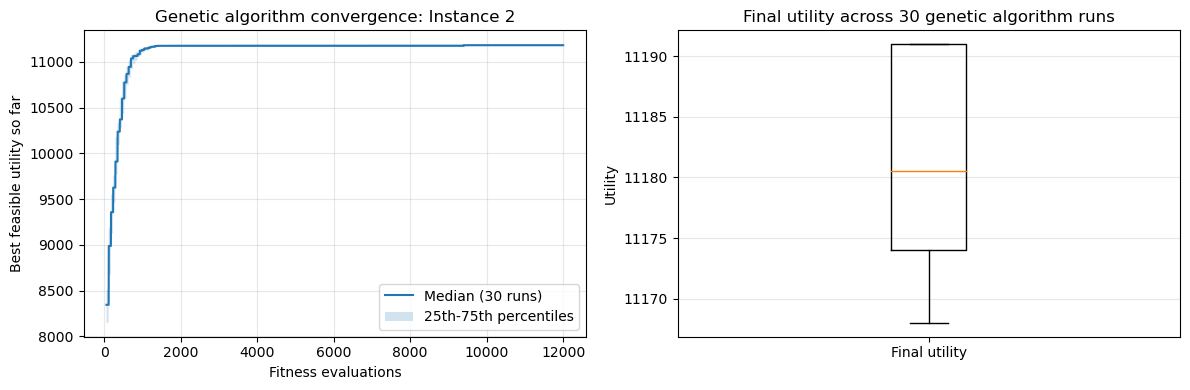

In [22]:
# Create a common evaluation axis.
ga_first_evaluation = max(
    run["history"][0][0]
    for run in ga_runs
)

ga_last_evaluation = max(
    run["evaluations"]
    for run in ga_runs
)

ga_evaluation_grid = np.arange(
    ga_first_evaluation,
    ga_last_evaluation + 1
)

ga_curves = []

for run in ga_runs:
    history = np.asarray(run["history"])

    # Carry the latest recorded best value forward
    # between recorded generations.
    indices = np.searchsorted(
        history[:, 0],
        ga_evaluation_grid,
        side="right"
    ) - 1

    ga_curves.append(history[indices, 1])

ga_curves = np.asarray(ga_curves)

ga_q25, ga_median_curve, ga_q75 = np.percentile(
    ga_curves,
    [25, 50, 75],
    axis=0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    ga_evaluation_grid,
    ga_median_curve,
    label="Median (30 runs)"
)

axes[0].fill_between(
    ga_evaluation_grid,
    ga_q25,
    ga_q75,
    alpha=0.2,
    label="25th-75th percentiles"
)

axes[0].set_xlabel(
    "Fitness evaluations"
)
axes[0].set_ylabel(
    "Best feasible utility so far"
)
axes[0].set_title(
    "Genetic algorithm convergence: Instance 2"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].boxplot(
    ga_final_values
)

axes[1].set_xticks([1])
axes[1].set_xticklabels(["Final utility"])
axes[1].set_ylabel("Utility")
axes[1].set_title(
    "Final utility across 30 genetic algorithm runs"
)
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

The left-hand plot shows how solution quality changes during the
search on Instance 2. The horizontal axis represents fitness
evaluations, including initialisation, and the vertical axis represents
the best feasible utility found so far.

At each evaluation point, the solid line shows the median best-so-far
utility across 30 independent runs. The shaded region covers the
25th–75th percentiles, representing the middle 50% of results rather
than a confidence interval. Values are recorded after each generation
and carried forward between recorded points.

Most improvement occurs within approximately the first 1,500
evaluations. The median curve then largely levels off, with only small
later improvements. This indicates diminishing improvement within the
remaining budget, but does not establish global optimality. The
best-so-far curve does not decrease because the algorithm retains its
best recorded solution and uses elitism.

The right-hand boxplot summarises the final utilities from these same
30 runs. The line inside the box is the median, and the box spans the
25th–75th percentiles. Whiskers extend to the most extreme observations
within 1.5 interquartile ranges of the box; observations beyond these
limits would appear as separate points.

The final utility values are similar across the 30 runs, but they
are not identical. Similar utility values also do not necessarily
mean that the same models were selected.

### 21. Technical Discussion

Across 30 independent runs on Instance 2, the genetic algorithm
achieved a mean final utility of 11,181.57 and a median of 11,180.50.
Final utilities ranged from 11,168 to 11,191, with a sample standard
deviation of 8.68. All final solutions were feasible.

The best observed solution used 1,777, 1,100, 2,259, 2,232 and 2,418
units of the five resources. Resource 2 was fully utilised, while
the other resources retained spare capacity. Remaining capacity
does not necessarily allow another model to be added because all
five constraints must be satisfied simultaneously.

Tournament selection favours higher-utility parents. Uniform crossover
recombines their selection decisions without assuming that adjacent
model indices have a meaningful relationship. A mutation rate of 1/90
produces approximately one flipped bit per offspring on average.
Elitism retains the two best individuals between generations.

Greedy repair restores feasibility by removing models with low utility
relative to normalised consumption of currently violated resources.
This can preserve useful models, but introduces a heuristic bias and
does not guarantee the best feasible repair.

Most improvement occurred early, followed by limited progress.
However, the curve alone cannot determine whether population diversity
was lost. The mean search time was 1.2086 seconds per run in the current
environment, using 12,000 evaluations per run.

These results describe performance on Instance 2 under the chosen
settings. They do not prove global optimality or establish superiority
over the Part 1 algorithm, which was tested on a different instance.

## Part 3: Empirical Study and Hypothesis Testing

This study compares two variants of the binary genetic algorithm
on Instance 2. The variants differ only in how infeasible offspring
are repaired: random removal or greedy removal.

### 22. Research Question and Hypothesis
Genetic algorithms incorporating problem-specific heuristic operators have been studied for the multidimensional knapsack problem (Chu & Beasley, 1998). This provides background for investigating repair strategies in the present study. The greedy repair rule used here is the utility-to-normalised-resource removal heuristic defined in Section 13.

Research question: Does greedy offspring repair produce higher final
feasible utility than random offspring repair under an equal
fitness-evaluation budget?

GA-Random repeatedly removes a randomly selected model until the
offspring is feasible. GA-Greedy uses the utility-to-normalised-resource
score defined in Section 13 to decide which model to remove.

We hypothesise that greedy repair will produce higher final utility
because it uses utility and resource information to guide removals,
whereas random repair may discard valuable models. However, greedy
repair requires additional calculations and may bias the search
towards similar solutions.

Both variants will use the same feasible initial population within
each experimental pair. Only offspring repair will differ. Population
size, selection, crossover, mutation, elitism and evaluation budget
will be held constant.

Each variant will be evaluated over 30 runs using seeds 0–29 and
12,000 fitness evaluations per run. Final utility, runtime and repair
effort will be recorded. The hypothesis will be assessed using the
observed results and a non-parametric statistical test.

### 23. Random Repair Operator

Random repair removes one selected model at a time until all resource
constraints are satisfied. It does not use utility values to guide
the removal decision.

The input solution is copied before modification. If the input solution already satisfies all resource constraints,
no models are removed.

In [23]:
def repair_solution_random(
    x,
    utilities,
    demands,
    capacities,
    rng
):
    """Remove randomly selected models until the solution is feasible."""
    repaired = np.asarray(x, dtype=np.int8).copy()

    while np.any(demands @ repaired > capacities):
        selected = np.flatnonzero(repaired == 1)

        remove_model = rng.choice(selected)
        repaired[remove_model] = 0

    return repaired

In [24]:
# Start with every model selected.
test_solution = np.ones(n2, dtype=np.int8)

random_repaired = repair_solution_random(
    test_solution,
    utilities2,
    demands2,
    capacities2,
    np.random.default_rng(42)
)

repair_value, repair_usage, repair_feasible = evaluate_solution(
    random_repaired,
    utilities2,
    demands2,
    capacities2
)

print("Utility after random repair:", repair_value)
print("Resource usage:", repair_usage)
print("Resource capacities:", capacities2)
print("Feasible after repair:", repair_feasible)
print("Number of selected models:", random_repaired.sum())
print("Original solution unchanged:", np.all(test_solution == 1))

Utility after random repair: 5251.0
Resource usage: [ 918. 1094.  995.  856. 1211.]
Resource capacities: [2100. 1100. 3300. 3700. 3600.]
Feasible after repair: True
Number of selected models: 27
Original solution unchanged: True


### 24. Controlled Experimental Protocol

The two variants differ only in their offspring repair strategy.
Within each pair, both variants start from the same feasible initial
population, constructed using the greedy initialisation procedure.

Both use a population size of 60, tournament size of 3, crossover
probability of 0.9, mutation probability of 1/90 and two elite individuals.
Each run has a budget of 12,000 fitness evaluations.

Initialisation, reproduction and repair use separate sources of
randomness. Random repair therefore does not change the sequence
of random numbers used for parent selection, crossover or mutation.

### 25. Genetic Algorithm with Configurable Offspring Repair

A shared implementation is used for both variants. The repair_method
argument selects either random or greedy offspring repair.

The initial population is identical within each experimental pair.
Fitness values are cached, and the evaluation counter includes every
initial individual and repaired offspring.

The best-so-far utility is recorded after every offspring evaluation.
Repair-stage timing includes resource checks, the repair operation
and the recording of repair statistics.

In [25]:
from time import perf_counter


def genetic_algorithm_comparison(
    utilities, demands, capacities,
    repair_method="greedy", seed=42,
    population_size=60, max_evaluations=12000,
    crossover_rate=0.9, mutation_rate=None,
    tournament_size=3, elite_count=2
):
    if repair_method not in ("random", "greedy"):
        raise ValueError("Unknown repair method.")

    if not 1 <= elite_count < population_size:
        raise ValueError("Invalid population size or elite count.")

    if max_evaluations < population_size:
        raise ValueError("Budget must cover the initial population.")

    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    if not 0 <= mutation_rate <= 1 or not 0 <= crossover_rate <= 1:
        raise ValueError("Probabilities must be between 0 and 1.")

    if tournament_size < 1:
        raise ValueError("Tournament size must be positive.")

    # Separate random sources for the three stages.
    rng_init = np.random.default_rng([seed, 0])
    rng_search = np.random.default_rng([seed, 1])
    rng_repair = np.random.default_rng([seed, 2])

    start = perf_counter()

    # Both variants use the same initialisation procedure.
    population = initialise_population(
        population_size, utilities, demands, capacities, rng_init
    )

    initial_population = population.copy()

    # Evaluate each initial individual once.
    initial_results = [
        evaluate_solution(x, utilities, demands, capacities)
        for x in population
    ]

    if not all(item[2] for item in initial_results):
        raise RuntimeError("Initial population is infeasible.")

    fitness = np.array([item[0] for item in initial_results])
    evaluations = population_size

    best_index = np.argmax(fitness)
    best_solution = population[best_index].copy()
    best_value = fitness[best_index]
    best_usage = initial_results[best_index][1].copy()

    initial_best = best_value
    history = [(evaluations, best_value)]

    # These statistics describe offspring repair.
    repair_calls = 0
    repair_needed = 0
    removed_models = 0
    repair_seconds = 0.0

    while evaluations < max_evaluations:
        ranking = np.argsort(fitness)[::-1][:elite_count]

        next_population = [
            population[i].copy() for i in ranking
        ]
        next_fitness = [
            fitness[i] for i in ranking
        ]

        while (
            len(next_population) < population_size
            and evaluations < max_evaluations
        ):
            parent_a = tournament_select(
                population, fitness, rng_search, tournament_size
            )
            parent_b = tournament_select(
                population, fitness, rng_search, tournament_size
            )

            child = uniform_crossover(
                parent_a, parent_b, rng_search, crossover_rate
            )
            child = bit_flip_mutation(
                child, rng_search, mutation_rate
            )

            # Apply the selected repair method and record its effort.
            repair_start = perf_counter()

            was_infeasible = bool(
                np.any(demands @ child > capacities)
            )
            selected_before = int(child.sum())

            if repair_method == "random":
                child = repair_solution_random(
                    child, utilities, demands, capacities, rng_repair
                )
            else:
                child = repair_solution_greedy(
                    child, utilities, demands, capacities
                )

            repair_calls += 1
            repair_needed += int(was_infeasible)
            removed_models += selected_before - int(child.sum())
            repair_seconds += perf_counter() - repair_start

            # Evaluate the repaired offspring exactly once.
            child_value, child_usage, feasible = evaluate_solution(
                child, utilities, demands, capacities
            )
            evaluations += 1

            if not feasible:
                raise RuntimeError(
                    "Repair produced an infeasible child."
                )

            next_population.append(child)
            next_fitness.append(child_value)

            if child_value > best_value:
                best_solution = child.copy()
                best_value = child_value
                best_usage = child_usage.copy()

            history.append((evaluations, best_value))

        population = np.asarray(
            next_population, dtype=np.int8
        )
        fitness = np.asarray(next_fitness)

    elapsed = perf_counter() - start

    return {
        "method": repair_method,
        "seed": seed,
        "solution": best_solution,
        "value": best_value,
        "usage": best_usage,
        "evaluations": evaluations,
        "history": history,
        "initial_best": initial_best,
        "initial_population": initial_population,
        "repair_calls": repair_calls,
        "repair_needed": repair_needed,
        "removed_models": removed_models,
        "repair_seconds": repair_seconds,
        "seconds": elapsed
    }

### 26. Paired Demonstration

Both variants are first run with seed 42. Their initial populations
and evaluation counts are checked before conducting the repeated study.

This single pair verifies the experimental setup; it is not sufficient
to establish which repair method performs better overall.

In [26]:
comparison_demo = {}

for method in ["random", "greedy"]:
    run = genetic_algorithm_comparison(
        utilities2,
        demands2,
        capacities2,
        repair_method=method,
        seed=42,
        population_size=60,
        max_evaluations=12000
    )

    # Validation after the search is outside its evaluation budget.
    checked_value, checked_usage, feasible = evaluate_solution(
        run["solution"],
        utilities2,
        demands2,
        capacities2
    )

    if not feasible or not np.isclose(checked_value, run["value"]):
        raise RuntimeError("Final solution validation failed.")

    comparison_demo[method] = run

    print("\nRepair method:", method)
    print("Initial best utility:", run["initial_best"])
    print("Final utility:", run["value"])
    print("Resource usage:", run["usage"])
    print("Evaluations:", run["evaluations"])
    print("Final solution feasible:", feasible)
    print("Offspring requiring repair:", run["repair_needed"])
    print("Total model removals:", run["removed_models"])
    print("Repair-stage time:", round(run["repair_seconds"], 4))
    print("Total search time:", round(run["seconds"], 4))

same_initial_population = np.array_equal(
    comparison_demo["random"]["initial_population"],
    comparison_demo["greedy"]["initial_population"]
)

print("\nSame initial population:", same_initial_population)


Repair method: random
Initial best utility: 8592.0
Final utility: 11191.0
Resource usage: [1777. 1100. 2259. 2232. 2418.]
Evaluations: 12000
Final solution feasible: True
Offspring requiring repair: 4011
Total model removals: 13203
Repair-stage time: 1.0096
Total search time: 2.0053

Repair method: greedy
Initial best utility: 8592.0
Final utility: 11187.0
Resource usage: [1783. 1100. 2187. 2136. 2446.]
Evaluations: 12000
Final solution feasible: True
Offspring requiring repair: 3998
Total model removals: 5136
Repair-stage time: 0.6182
Total search time: 1.4991

Same initial population: True


For seed 42, both variants started from the same initial population
and used 12,000 fitness evaluations. Both final solutions were feasible.

Random repair achieved a final utility of 11,191, compared with 11,187
for greedy repair. Greedy repair removed fewer models in total:
5,136 compared with 13,203. Its repair-stage time and total search
time were also lower in this run.

This pair illustrates a trade-off between final utility and repair
effort. It does not establish which method performs better across
independent runs. Repeated experiments and statistical testing are
required to assess the research hypothesis.

### 27. Thirty Paired Experiments

Thirty paired experiments are conducted using seeds 0–29.
Each pair contains one GA-Random run and one GA-Greedy run,
starting from identical feasible initial populations.

All algorithm parameters are held constant. Each run uses
12,000 fitness evaluations. The order of the two variants is
alternated between pairs to reduce systematic timing effects
associated with always running one variant first.

After each run, the final utility, resource usage and feasibility
are checked. Initial populations are compared within every pair.
These validation checks are outside the timed search and its
fitness-evaluation budget.

In [27]:
comparison_seeds = list(range(30))
comparison_budget = 12000
comparison_population_size = 60

# Reset storage whenever this cell is rerun.
comparison_runs = {
    "random": [],
    "greedy": []
}

for seed in comparison_seeds:
    # Alternate which variant runs first.
    method_order = (
        ["random", "greedy"] if seed % 2 == 0
        else ["greedy", "random"]
    )

    pair = {}

    for method in method_order:
        run = genetic_algorithm_comparison(
            utilities2,
            demands2,
            capacities2,
            repair_method=method,
            seed=seed,
            population_size=comparison_population_size,
            max_evaluations=comparison_budget,
            crossover_rate=0.9,
            mutation_rate=1 / n2,
            tournament_size=3,
            elite_count=2
        )

        # Validate after the timed search.
        checked_value, checked_usage, feasible = evaluate_solution(
            run["solution"],
            utilities2,
            demands2,
            capacities2
        )

        if not feasible:
            raise RuntimeError(
                f"Infeasible result: seed={seed}, method={method}"
            )

        if not np.isclose(checked_value, run["value"]):
            raise RuntimeError(
                "Stored utility does not match checked utility."
            )

        if not np.allclose(checked_usage, run["usage"]):
            raise RuntimeError(
                "Stored resource usage does not match checked usage."
            )

        if run["evaluations"] != comparison_budget:
            raise RuntimeError("Evaluation budget mismatch.")

        expected_offspring = (
            comparison_budget - comparison_population_size
        )

        if run["repair_calls"] != expected_offspring:
            raise RuntimeError("Offspring count mismatch.")

        run["feasible"] = feasible
        pair[method] = run

    # Confirm identical starting populations.
    if not np.array_equal(
        pair["random"]["initial_population"],
        pair["greedy"]["initial_population"]
    ):
        raise RuntimeError(
            f"Initial populations differ for seed {seed}."
        )

    # Save both runs only after the pair passes validation.
    for method in ["random", "greedy"]:
        comparison_runs[method].append(pair[method])

    print(
        f"Pair {seed + 1:02d}/30 | seed={seed:2d} | "
        f"Random={pair['random']['value']:.0f} | "
        f"Greedy={pair['greedy']['value']:.0f}",
        flush=True
    )

print("\nCompleted 30 paired experiments: 60 algorithm runs.")

for method in ["random", "greedy"]:
    records = comparison_runs[method]

    print(
        f"{method}: {len(records)} runs; "
        f"{sum(run['feasible'] for run in records)} feasible; "
        f"{comparison_budget} evaluations per run."
    )

print("Identical initial populations verified in all 30 pairs.")

Pair 01/30 | seed= 0 | Random=11168 | Greedy=11191
Pair 02/30 | seed= 1 | Random=11156 | Greedy=11191
Pair 03/30 | seed= 2 | Random=11187 | Greedy=11187
Pair 04/30 | seed= 3 | Random=11165 | Greedy=11191
Pair 05/30 | seed= 4 | Random=11162 | Greedy=11187
Pair 06/30 | seed= 5 | Random=11178 | Greedy=11191
Pair 07/30 | seed= 6 | Random=11175 | Greedy=11187
Pair 08/30 | seed= 7 | Random=11172 | Greedy=11174
Pair 09/30 | seed= 8 | Random=11169 | Greedy=11191
Pair 10/30 | seed= 9 | Random=11161 | Greedy=11187
Pair 11/30 | seed=10 | Random=11168 | Greedy=11172
Pair 12/30 | seed=11 | Random=11187 | Greedy=11187
Pair 13/30 | seed=12 | Random=11146 | Greedy=11187
Pair 14/30 | seed=13 | Random=11182 | Greedy=11174
Pair 15/30 | seed=14 | Random=11191 | Greedy=11172
Pair 16/30 | seed=15 | Random=11187 | Greedy=11191
Pair 17/30 | seed=16 | Random=11187 | Greedy=11187
Pair 18/30 | seed=17 | Random=11187 | Greedy=11174
Pair 19/30 | seed=18 | Random=11160 | Greedy=11174
Pair 20/30 | seed=19 | Random=1